# CFKS Burgers $\nu=0.01$ — Stage 01 multiscale predictor

Direct solve at $\nu=0.01$ with **no viscosity continuation**. The kernel is fixed throughout:

\[
k_{\rm MS}=\widehat{k}_g+0.3\,\widehat{k}_\ell,
\]

with a global continuum-feature mean kernel and a narrow local continuum-feature mean kernel centered around the internal-layer region. Collocation sites are also the kernel representer sites. Stage 01 uses 10 deterministic Halton PDE points per spatial block and generates an independent residual-attention map for Stage 02.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from numpy.polynomial.legendre import leggauss
from scipy.special import erf
from scipy.linalg import svd
from scipy.optimize import least_squares
from scipy.interpolate import CubicSpline

# ---------------------------------------------------------------------
# Problem and slab configuration
# ---------------------------------------------------------------------
XL, XR = -1.0, 1.0
NU = 0.01
T_FINAL = 1.0
N_SLABS = 40
DT = T_FINAL / N_SLABS

# Fixed multiscale continuum-feature mean kernel
SIGMA_X_GLOBAL = 0.10*2
SIGMA_T_GLOBAL = 0.020*2
SIGMA_X_LOCAL = 0.015*4
SIGMA_T_LOCAL = 0.015*4
LOCAL_SUPPORT = (-0.30, 0.30)
ETA_LOCAL = 0.30

GLOBAL_TIME_SUPPORT = (-0.04, DT + 0.04)
LOCAL_TIME_SUPPORT = (-0.035, DT + 0.035)
GLOBAL_X_SUPPORT = (XL - 0.30, XR + 0.30)

# Spatial attention blocks
N_BLOCKS = 20
X_EDGES = np.linspace(XL, XR, N_BLOCKS + 1)

# Dense transfer grid between slabs
N_TRANSFER = 1201
X_TRANSFER = np.linspace(XL, XR, N_TRANSFER)

# Nonlinear solve settings
MAX_NFEV = 20
RIDGE_PREDICTOR = 1e-8
RIDGE_PICARD = 1e-9


def radical_inverse(n, b):
    n = np.asarray(n, dtype=int).copy()
    r = np.zeros_like(n, dtype=float)
    f = 1.0 / b
    while np.any(n > 0):
        r += f * (n % b)
        n //= b
        f /= b
    return r


def halton_2d_prefix(N):
    idx = np.arange(1, N + 1)
    return radical_inverse(idx, 2), radical_inverse(idx, 3)


def _moments(mu, sigma, ca, cb, nmax=2):
    A = ca - mu
    B = cb - mu
    J = [None] * (nmax + 1)
    J[0] = 0.5*np.sqrt(np.pi)*sigma*(erf(B/sigma) - erf(A/sigma))
    J[1] = 0.5*sigma**2*(np.exp(-(A/sigma)**2) - np.exp(-(B/sigma)**2))
    for n in range(2, nmax + 1):
        boundary = B**(n-1)*np.exp(-(B/sigma)**2) - A**(n-1)*np.exp(-(A/sigma)**2)
        J[n] = -0.5*sigma**2*boundary + 0.5*(n-1)*sigma**2*J[n-2]
    return J


def mean_kernel_1d(x, y, sigma, ca, cb, order_x=0):
    """Exact bounded Gaussian-RBF continuum-feature mean kernel.

    order_x=0,1,2 differentiates with respect to the first argument.
    """
    x = np.asarray(x, float).reshape(-1, 1)
    y = np.asarray(y, float).reshape(1, -1)
    m = 0.5*(x + y)
    d = x - y
    pref = np.exp(-(d*d)/(4.0*sigma*sigma)) / (cb - ca)
    J = _moments(m, sigma, ca, cb, 2)
    if order_x == 0:
        poly = J[0]
    elif order_x == 1:
        poly = (J[1] - 0.5*d*J[0]) / sigma**2
    elif order_x == 2:
        poly = ((J[2] - d*J[1] + 0.25*d*d*J[0]) / sigma**4
                - J[0] / sigma**2)
    else:
        raise NotImplementedError
    return pref * poly


def component_norm(sigma_x, sigma_t, cx_a, cx_b, ct_a, ct_b):
    kx = mean_kernel_1d([0.0], [0.0], sigma_x, cx_a, cx_b, 0)[0, 0]
    kt = mean_kernel_1d([0.5*DT], [0.5*DT], sigma_t, ct_a, ct_b, 0)[0, 0]
    return float(kx*kt)


GLOBAL_CFG = (SIGMA_X_GLOBAL, SIGMA_T_GLOBAL,
              GLOBAL_X_SUPPORT[0], GLOBAL_X_SUPPORT[1],
              GLOBAL_TIME_SUPPORT[0], GLOBAL_TIME_SUPPORT[1])
LOCAL_CFG = (SIGMA_X_LOCAL, SIGMA_T_LOCAL,
             LOCAL_SUPPORT[0], LOCAL_SUPPORT[1],
             LOCAL_TIME_SUPPORT[0], LOCAL_TIME_SUPPORT[1])

GLOBAL_NORM = component_norm(*GLOBAL_CFG)
LOCAL_NORM = component_norm(*LOCAL_CFG)


def kernel_component(x, tau, zx, ztau, cfg, norm):
    sx, st, cxa, cxb, cta, ctb = cfg
    Kx0 = mean_kernel_1d(x, zx, sx, cxa, cxb, 0)
    Kx1 = mean_kernel_1d(x, zx, sx, cxa, cxb, 1)
    Kx2 = mean_kernel_1d(x, zx, sx, cxa, cxb, 2)
    Kt0 = mean_kernel_1d(tau, ztau, st, cta, ctb, 0)
    Kt1 = mean_kernel_1d(tau, ztau, st, cta, ctb, 1)
    return (Kx0*Kt0/norm,
            Kx1*Kt0/norm,
            Kx2*Kt0/norm,
            Kx0*Kt1/norm)


def multiscale_kernel_matrices(x, tau, zx, ztau):
    G = kernel_component(x, tau, zx, ztau, GLOBAL_CFG, GLOBAL_NORM)
    L = kernel_component(x, tau, zx, ztau, LOCAL_CFG, LOCAL_NORM)
    return tuple(G[i] + ETA_LOCAL*L[i] for i in range(4))


def make_collocation(counts_per_block):
    xs, ts, block_ids = [], [], []
    for j, n in enumerate(np.asarray(counts_per_block, int)):
        hx, ht = halton_2d_prefix(int(n))
        xa, xb = X_EDGES[j], X_EDGES[j+1]
        xs.extend(xa + (xb-xa)*hx)
        ts.extend(DT*ht)
        block_ids.extend([j]*int(n))
    return np.asarray(xs), np.asarray(ts), np.asarray(block_ids, int)


def build_trial_operators(xc, tc):
    # Collocation sites ARE the kernel representer sites.
    K0, Kx, Kxx, Kt = multiscale_kernel_matrices(xc, tc, xc, tc)
    S = tc*(1.0 - xc**2)
    St = 1.0 - xc**2
    Sx = -2.0*xc*tc
    Sxx = -2.0*tc
    Du = S[:, None]*K0
    Dux = Sx[:, None]*K0 + S[:, None]*Kx
    Duxx = Sxx[:, None]*K0 + 2.0*Sx[:, None]*Kx + S[:, None]*Kxx
    Dut = St[:, None]*K0 + S[:, None]*Kt
    return Du, Dux, Duxx, Dut


def ridge_svd(A, b, ridge_rel):
    U, s, Vh = svd(A, full_matrices=False, check_finite=False)
    lam = ridge_rel * s[0]**2
    return Vh.T @ ((s/(s*s + lam)) * (U.T @ b))


def solve_one_slab(uin_spline, counts_per_block):
    xc, tc, block_id = make_collocation(counts_per_block)
    Du, Dux, Duxx, Dut = build_trial_operators(xc, tc)

    uin = uin_spline(xc)
    uinx = uin_spline(xc, 1)
    uinxx = uin_spline(xc, 2)

    # A. Frozen-advection linearized predictor
    A = Dut + uin[:, None]*Dux - NU*Duxx
    b = NU*uinxx - uin*uinx
    alpha = ridge_svd(A, b, RIDGE_PREDICTOR)

    # B. One Picard update
    up = uin + Du @ alpha
    A2 = Dut + up[:, None]*Dux - NU*Duxx
    b2 = NU*uinxx - up*uinx
    alpha = ridge_svd(A2, b2, RIDGE_PICARD)

    # C. Full nonlinear Burgers corrector
    def residual(a):
        u = uin + Du @ a
        ux = uinx + Dux @ a
        uxx = uinxx + Duxx @ a
        ut = Dut @ a
        return ut + u*ux - NU*uxx

    def jacobian(a):
        u = uin + Du @ a
        ux = uinx + Dux @ a
        return Dut + ux[:, None]*Du + u[:, None]*Dux - NU*Duxx

    rms_before = np.sqrt(np.mean(residual(alpha)**2))
    opt = least_squares(
        residual, alpha, jac=jacobian,
        method='trf', tr_solver='lsmr', x_scale=1.0,
        ftol=1e-8, xtol=1e-8, gtol=1e-8,
        max_nfev=MAX_NFEV, verbose=0,
    )
    alpha = opt.x
    rms_after = np.sqrt(np.mean(residual(alpha)**2))
    return alpha, xc, tc, block_id, rms_before, rms_after, opt.nfev


def evaluate_solution(uin_spline, alpha, xc, tc, xq, tq, derivatives=False):
    xq = np.asarray(xq, float).ravel()
    tq = np.asarray(tq, float).ravel()
    K0, Kx, Kxx, Kt = multiscale_kernel_matrices(xq, tq, xc, tc)
    S = tq*(1.0 - xq**2)
    St = 1.0 - xq**2
    Sx = -2.0*xq*tq
    Sxx = -2.0*tq
    Du = S[:, None]*K0
    u = uin_spline(xq) + Du @ alpha
    if not derivatives:
        return u
    Dux = Sx[:, None]*K0 + S[:, None]*Kx
    Duxx = Sxx[:, None]*K0 + 2.0*Sx[:, None]*Kx + S[:, None]*Kxx
    Dut = St[:, None]*K0 + S[:, None]*Kt
    ux = uin_spline(xq, 1) + Dux @ alpha
    uxx = uin_spline(xq, 2) + Duxx @ alpha
    ut = Dut @ alpha
    return u, ux, uxx, ut


def terminal_profile(uin_spline, alpha, xc, tc):
    tq = np.full_like(X_TRANSFER, DT)
    uend = evaluate_solution(uin_spline, alpha, xc, tc, X_TRANSFER, tq)
    # Enforce only the prescribed homogeneous boundary values. No odd-symmetry projection.
    uend[0] = 0.0
    uend[-1] = 0.0
    return CubicSpline(X_TRANSFER, uend), uend


# Independent residual probes used to build attention / validate Stage 2.
PROBE_NX = 11
PROBE_NT = 7
PROBE_TAU_FRAC = np.linspace(0.08, 0.96, PROBE_NT)


def block_residual_statistics(uin_spline, alpha, xc, tc):
    rms = np.zeros(N_BLOCKS)
    maxabs = np.zeros(N_BLOCKS)
    for j in range(N_BLOCKS):
        xa, xb = X_EDGES[j], X_EDGES[j+1]
        xp = np.linspace(xa + 0.05*(xb-xa), xb - 0.05*(xb-xa), PROBE_NX)
        tp = DT*PROBE_TAU_FRAC
        X, T = np.meshgrid(xp, tp, indexing='xy')
        xq, tq = X.ravel(), T.ravel()
        u, ux, uxx, ut = evaluate_solution(uin_spline, alpha, xc, tc, xq, tq, True)
        r = ut + u*ux - NU*uxx
        rms[j] = np.sqrt(np.mean(r*r))
        maxabs[j] = np.max(np.abs(r))
    eps = 1e-14
    score = 0.70*rms/(rms.max()+eps) + 0.30*maxabs/(maxabs.max()+eps)
    return score, rms, maxabs


def dilate_nonperiodic(mask, radius):
    mask = np.asarray(mask, bool)
    out = mask.copy()
    for j in np.flatnonzero(mask):
        out[max(0, j-radius):min(mask.size, j+radius+1)] = True
    return out


def attention_to_levels(score, theta_mid=0.10, theta_high=0.35,
                        high_radius=1, mid_radius=1):
    score = np.asarray(score, float)
    high_raw = score >= theta_high
    mid_raw = score >= theta_mid
    if not np.any(high_raw):
        high_raw[np.argmax(score)] = True
    high = dilate_nonperiodic(high_raw, high_radius)
    mid = dilate_nonperiodic(mid_raw | high_raw, mid_radius)
    levels = np.ones(score.size, dtype=int)
    levels[mid] = 2
    levels[high] = 3
    return levels


def cole_hopf_reference(x, t, nu=NU, nq=800, image_radius=2):
    """Stable Cole-Hop reference via Neumann heat-kernel convolution."""
    x = np.asarray(x, float).ravel()
    if float(t) == 0.0:
        return -np.sin(np.pi*x)
    y, w = leggauss(nq)
    phi0 = np.exp(-np.cos(np.pi*y)/(2.0*nu*np.pi))
    phi0 /= phi0.max()
    den = 4.0*nu*float(t)
    pref = 1.0/np.sqrt(np.pi*den)
    weighted_phi0 = w*phi0
    out = np.empty_like(x)
    for i0 in range(0, x.size, 200):
        xx = x[i0:i0+200, None]
        G = np.zeros((xx.shape[0], y.size))
        Gx = np.zeros_like(G)
        for m in range(-image_radius, image_radius + 1):
            s1 = xx - y[None, :] + 4.0*m
            s2 = xx + y[None, :] + 2.0 + 4.0*m
            for s in (s1, s2):
                g = pref*np.exp(-(s*s)/den)
                G += g
                Gx += (-2.0*s/den)*g
        phi = (G*weighted_phi0[None, :]).sum(axis=1)
        phix = (Gx*weighted_phi0[None, :]).sum(axis=1)
        out[i0:i0+200] = -2.0*nu*phix/phi
    return out


In [2]:
# Stage-01 coarse predictor march
COUNTS_STAGE1 = np.full(N_BLOCKS, 10, dtype=int)

u_initial = -np.sin(np.pi*X_TRANSFER)
current_spline = CubicSpline(X_TRANSFER, u_initial)

levels_all = []
scores_all = []
probe_rms_all = []
probe_max_all = []
train_rms_before = []
train_rms_after = []
profiles = {0.0: u_initial.copy()}
store_steps = {10:0.25, 20:0.50, 30:0.75, 40:1.00}

t0 = time.perf_counter()
for n in range(1, N_SLABS + 1):
    alpha, xc, tc, block_id, r0, rf, nfev = solve_one_slab(current_spline, COUNTS_STAGE1)
    score, rrms, rmax = block_residual_statistics(current_spline, alpha, xc, tc)
    levels = attention_to_levels(score)

    levels_all.append(levels)
    scores_all.append(score)
    probe_rms_all.append(rrms)
    probe_max_all.append(rmax)
    train_rms_before.append(r0)
    train_rms_after.append(rf)

    current_spline, uend = terminal_profile(current_spline, alpha, xc, tc)
    if n in store_steps:
        profiles[store_steps[n]] = uend.copy()

    if n <= 3 or n % 5 == 0:
        bc = np.bincount(levels, minlength=4)[1:]
        print(f"slab {n:02d}/{N_SLABS}, t={n*DT:5.3f}, "
              f"train rms={rf:.3e}, levels low/mid/high={bc.tolist()}")

elapsed = time.perf_counter() - t0
print(f"\nStage-01 elapsed time: {elapsed:.2f} s")


slab 01/40, t=0.025, train rms=3.123e-03, levels low/mid/high=[0, 8, 12]
slab 02/40, t=0.050, train rms=2.288e-03, levels low/mid/high=[0, 0, 20]
slab 03/40, t=0.075, train rms=3.712e-03, levels low/mid/high=[0, 3, 17]
slab 05/40, t=0.125, train rms=7.305e-03, levels low/mid/high=[0, 6, 14]
slab 10/40, t=0.250, train rms=3.205e-02, levels low/mid/high=[7, 6, 7]
slab 15/40, t=0.375, train rms=6.806e-01, levels low/mid/high=[9, 5, 6]
slab 20/40, t=0.500, train rms=1.526e+00, levels low/mid/high=[10, 4, 6]
slab 25/40, t=0.625, train rms=1.433e+00, levels low/mid/high=[10, 5, 5]
slab 30/40, t=0.750, train rms=1.140e+00, levels low/mid/high=[10, 5, 5]
slab 35/40, t=0.875, train rms=8.786e-01, levels low/mid/high=[9, 6, 5]
slab 40/40, t=1.000, train rms=6.772e-01, levels low/mid/high=[6, 8, 6]

Stage-01 elapsed time: 21.25 s


In [3]:
# Validate Stage-01 predictor at representative times
validation_times = [0.25, 0.50, 0.75, 1.00]
print("\nStage-01 predictor errors")
print(" t       RMSE          max|error|")
print("-----------------------------------")
validation_rows = []
for tt in validation_times:
    ref = cole_hopf_reference(X_TRANSFER, tt)
    err = profiles[tt] - ref
    rmse = np.sqrt(np.mean(err*err))
    emax = np.max(np.abs(err))
    validation_rows.append((tt, rmse, emax))
    print(f"{tt:4.2f}   {rmse:11.4e}   {emax:11.4e}")



Stage-01 predictor errors
 t       RMSE          max|error|
-----------------------------------
0.25    9.0234e-04    4.6916e-03
0.50    4.6472e-02    3.3182e-01
0.75    5.9720e-02    4.1633e-01
1.00    4.8290e-02    3.0107e-01


In [4]:
# Save attention map and Stage-01 diagnostics for Stage 02
np.savez_compressed(
    "CFKS_BURGERS_MS_NU001_STAGE01_ATTENTION.npz",
    levels=np.asarray(levels_all, int),
    scores=np.asarray(scores_all, float),
    probe_rms=np.asarray(probe_rms_all, float),
    probe_max=np.asarray(probe_max_all, float),
    train_rms_before=np.asarray(train_rms_before, float),
    train_rms_after=np.asarray(train_rms_after, float),
    x_edges=X_EDGES,
    x_transfer=X_TRANSFER,
    predictor_t025=profiles[0.25],
    predictor_t050=profiles[0.50],
    predictor_t075=profiles[0.75],
    predictor_t100=profiles[1.00],
    predictor_validation=np.asarray(validation_rows, float),
    nu=NU,
    n_slabs=N_SLABS,
    dt=DT,
    sigma_x_global=SIGMA_X_GLOBAL,
    sigma_t_global=SIGMA_T_GLOBAL,
    sigma_x_local=SIGMA_X_LOCAL,
    sigma_t_local=SIGMA_T_LOCAL,
    eta_local=ETA_LOCAL,
)
print("Saved CFKS_BURGERS_MS_NU001_STAGE01_ATTENTION.npz")


Saved CFKS_BURGERS_MS_NU001_STAGE01_ATTENTION.npz


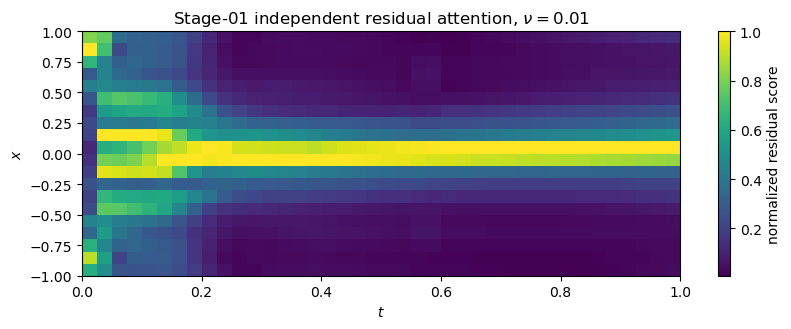

In [5]:
# Stage-01 attention map
A = np.asarray(scores_all)
fig, ax = plt.subplots(figsize=(8.5, 3.4))
im = ax.imshow(A.T, origin='lower', aspect='auto',
               extent=[0, T_FINAL, XL, XR])
ax.set_xlabel(r'$t$')
ax.set_ylabel(r'$x$')
ax.set_title(r'Stage-01 independent residual attention, $\nu=0.01$')
fig.colorbar(im, ax=ax, label='normalized residual score')
fig.tight_layout()
fig.savefig('CFKS_BURGERS_MS_NU001_STAGE01_ATTENTION.png', dpi=220, bbox_inches='tight')
plt.show()
